In [1]:
from test_beta_package import *
%matplotlib inline

In [2]:
# general check of the folder structure and assign variables
path_data_folder, path_raw_data_folder, path_process_data_folder, path_top_folder, path_info_dir, path_analysis_dir, \
path_plots_dir, path_single_pred_dir, path_multi_pred_dir = folder_structure()

In [3]:
#load the pickle files and assign dictionary to variables
data_continous_ratemaps, data_binned_glm = \
    processing_and_loading(path_raw_data_folder, path_process_data_folder, 
                           data_continous_ratemaps_pickle="rm_pre_data_diana_chasing2_notreheaded_XYZeuler_notricks_eo.pkl",
                           data_binned_glm_pickle="binned_4_GLM_rm_pre_data_diana_chasing2_notreheaded_XYZeuler_notricks_eo.pkl")


In [4]:
# obtain the information and save them for further processing
predictors_name_list, cells_id, animal_name = get_data_information(path_info_dir, data_continous_ratemaps)

In [5]:
# assign values to the model's parameters
dict_param = dict_parameters_hmm(path_info_dir, animal_name, num_dimen=1, num_categ_obs=2, N_iters=2,
                                 tolerance=10**-5, num_indep_neurons=2, num_predictors=5, max_num_states=3,
                                 observation_type="input_driven_obs",
                                 transistion_type="inputdriven", optim_method="em")

In [6]:
# extract the indices and totaltime from spike trains. With this function you select "num_indep_neurons" cells randomly
cell_index, tot_time = cells_selection_manual(path_info_dir, data_continous_ratemaps, data_binned_glm, dict_param, 'cells_selection.csv')


In [7]:
# %%capture cap --no-stderr 
# processing of data and creation of instances for the inference
glmhmms_ista, process_neur, inputs_list, T_list, tot_masked_indices_list, path_plots_list, plots_folder = \
    data_structure(path_info_dir, path_analysis_dir, path_single_pred_dir, data_continous_ratemaps, data_binned_glm,
                   dict_param,
                   tot_time, cell_index, predictor_file='test_predictors.csv')

the iloc approach is 0            B Speeds
1    G Neck_elevation
2    K Ego3_Head_roll
3        N Back_pitch
4    B Speeds_1st_der
Name: Predictors', dtype: object
loading file I obtain ['B Speeds', 'G Neck_elevation', 'K Ego3_Head_roll', 'N Back_pitch', 'B Speeds_1st_der']
NAME OF THE FOLDER IS C:\Users\teof\PycharmProjects\pythonREGITglmhmm\postural_glm_hmm\results_folder\plots_dir/single_pred_dir/diana_notreheaded_singlepredictor_2022-10-26_run/
IMPORTANT: given the presence of nans (missing points of the camera) part of the data are deleted.If the number of missing points is 'small enough', it should not interfere with the inference.Below the ratio of missing points
predictor list ['B Speeds', 'G Neck_elevation', 'K Ego3_Head_roll', 'N Back_pitch', 'B Speeds_1st_der']
[nan nan nan ... nan nan nan]
[ 7.84533631  7.84695203  7.85171584 ... 11.16635283 11.18234474
 11.24178234]
[5.62521328 6.05557478 6.2165284  ...        nan        nan        nan]
[ -9.32267933  -9.2959323   -9.71868

In [8]:
# fitting section, where you run the inference
fit_ll_states_list, glmhmms_ista, time_states_comp = inference_section(path_analysis_dir, path_info_dir, dict_param,
                                                                       glmhmms_ista=glmhmms_ista, process_neur=process_neur,
                                                                       inputs_list=inputs_list)

0


  0%|          | 0/2 [00:00<?, ?it/s]

computation time loop 0 is 1.7771570682525635
1


  0%|          | 0/2 [00:00<?, ?it/s]

computation time loop 1 is 1.3902111053466797
2


  0%|          | 0/2 [00:00<?, ?it/s]

... (11 outputs left out)

  0%|          | 0/2 [00:00<?, ?it/s]

computation time loop 8 is 1.470762014389038
4


  0%|          | 0/2 [00:00<?, ?it/s]

computation time loop 9 is 1.8362407684326172
The total time for the inference is 16.620292901992798


In [9]:
# post analysis processing. Here you obtain the posterior probabilities list with structure described in the code
posterior_probs_list = posterior_prob_process(path_info_dir, path_analysis_dir, dict_param=dict_param,
                                              glmhmms_ista=glmhmms_ista, process_neur=process_neur,
                                              inputs_list=inputs_list)

the input form is [[array([[10.6933533 ,  1.        ],
       [10.94194185,  1.        ],
       [11.20825033,  1.        ],
       ...,
       [ 0.37459429,  1.        ],
       [ 0.50266247,  1.        ],
       [ 0.64292032,  1.        ]]), array([[10.6933533 ,  1.        ],
       [10.94194185,  1.        ],
       [11.20825033,  1.        ],
       ...,
       [ 0.37459429,  1.        ],
       [ 0.50266247,  1.        ],
       [ 0.64292032,  1.        ]])], [array([[ 7.84533631,  1.        ],
       [ 7.84695203,  1.        ],
       [ 7.85171584,  1.        ],
       ...,
       [11.16635283,  1.        ],
       [11.18234474,  1.        ],
       [11.24178234,  1.        ]]), array([[ 7.84533631,  1.        ],
       [ 7.84695203,  1.        ],
       [ 7.85171584,  1.        ],
       ...,
       [11.16635283,  1.        ],
       [11.18234474,  1.        ],
       [11.24178234,  1.        ]])], [array([[5.62521328, 1.        ],
       [6.05557478, 1.        ],
       [6.2165

In [10]:
# further processing of posterior to get the total occupancy for each state
states_occupancies = states_occupancies_computation(path_analysis_dir, posterior_probs_list)

In [11]:
# Below s a sample of plots

2 5


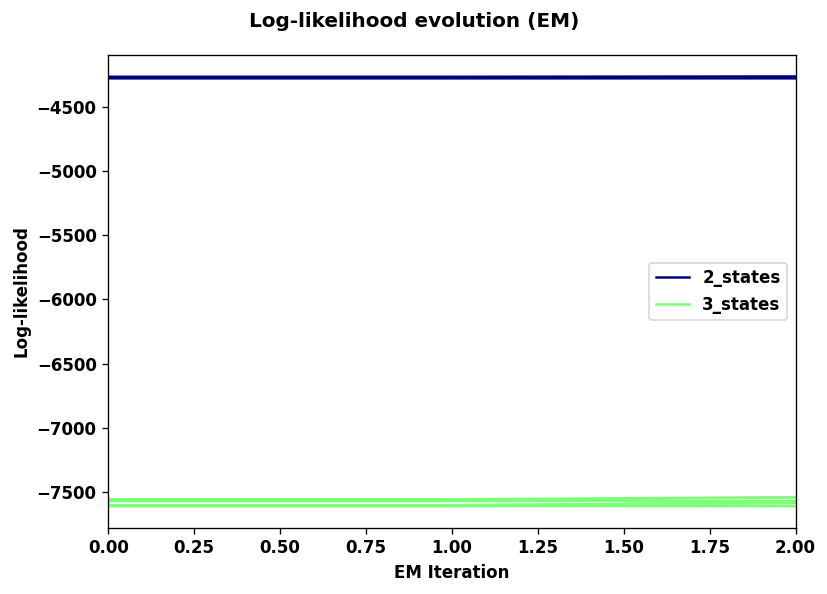

In [12]:
log_like_evolution_per_states(path_analysis_dir, path_info_dir, dict_objects=0, dict_processed_objects=0,
                              dictionary_information=0)

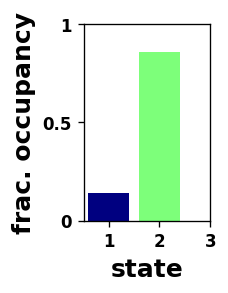

In [13]:
states_occupancies_histogram(path_analysis_dir, path_info_dir, dict_param=dict_param,
                             states_occupancies=states_occupancies)

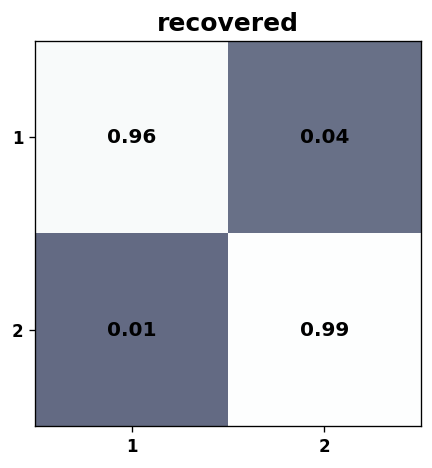

In [14]:
transition_prob_matrix(path_analysis_dir, path_info_dir, glmhmms_ista=glmhmms_ista, dict_param=dict_param)

inferred and transformed weights are {'2_states': [array([[[0.55432325, 0.98467038]],

       [[0.50094639, 0.98910154]]]), array([[[0.502212  , 0.98895581]],

       [[0.50119084, 0.98920136]]]), array([[[0.50064787, 0.98833721]],

       [[0.49859778, 0.98957215]]]), array([[[0.50270643, 0.99097707]],

       [[0.50197361, 0.98923703]]]), array([[[0.4996405 , 0.98863281]],

       [[0.50011164, 0.98939216]]])], '3_states': [array([[[0.4979013 , 0.98504709]],

       [[0.58235726, 0.9758061 ]]]), array([[[0.52738185, 0.94952119]],

       [[0.52791635, 0.95036609]]]), array([[[0.50524096, 0.9738964 ]],

       [[0.49685437, 0.97550321]]]), array([[[0.49986277, 0.97818134]],

       [[0.49990524, 0.97901108]]]), array([[[0.4995197 , 0.98053996]],

       [[0.50026205, 0.97956153]]])]}


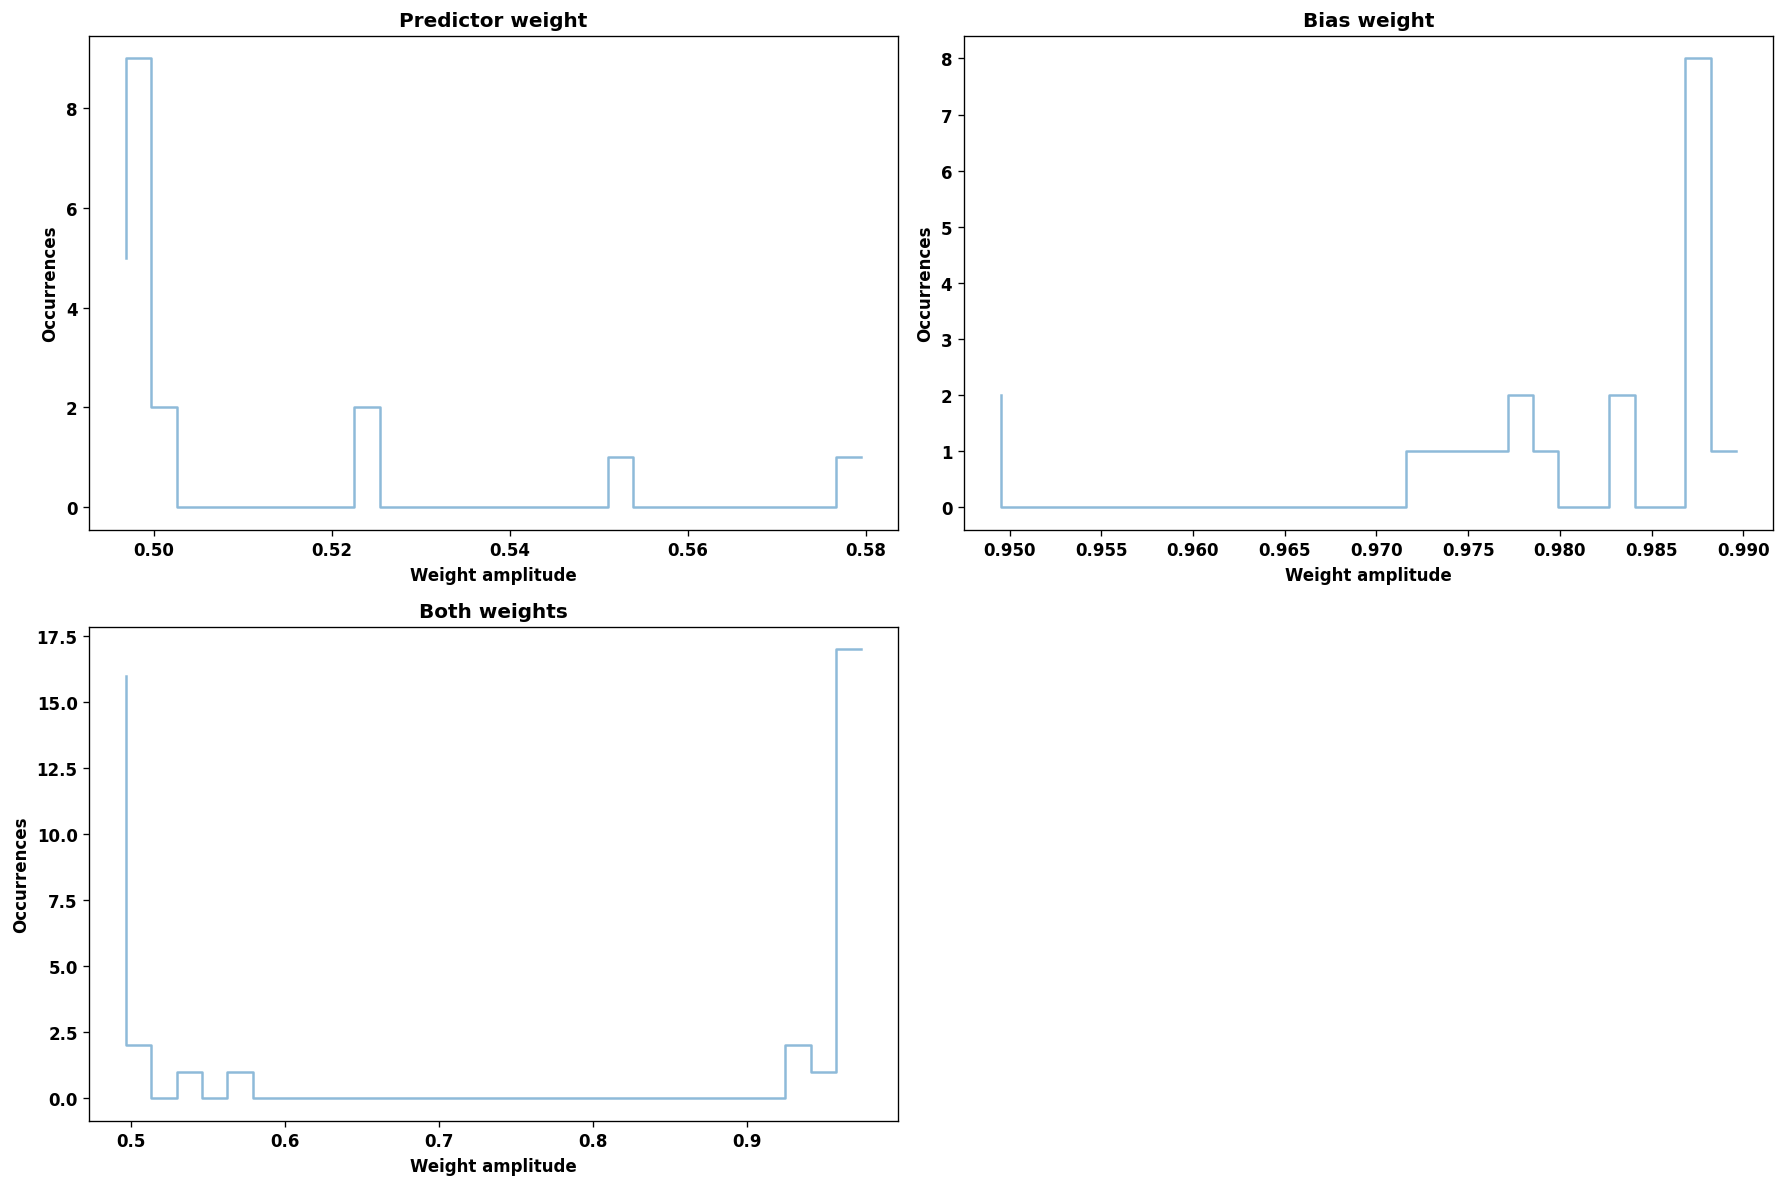

In [15]:
weights_distribution_histogram(path_analysis_dir, path_info_dir)

K Ego3_Head_roll
max value is 95.10858320869936
[0.05914517 0.06367012 0.06536243 ... 0.04252059 0.04551745 0.04919839]


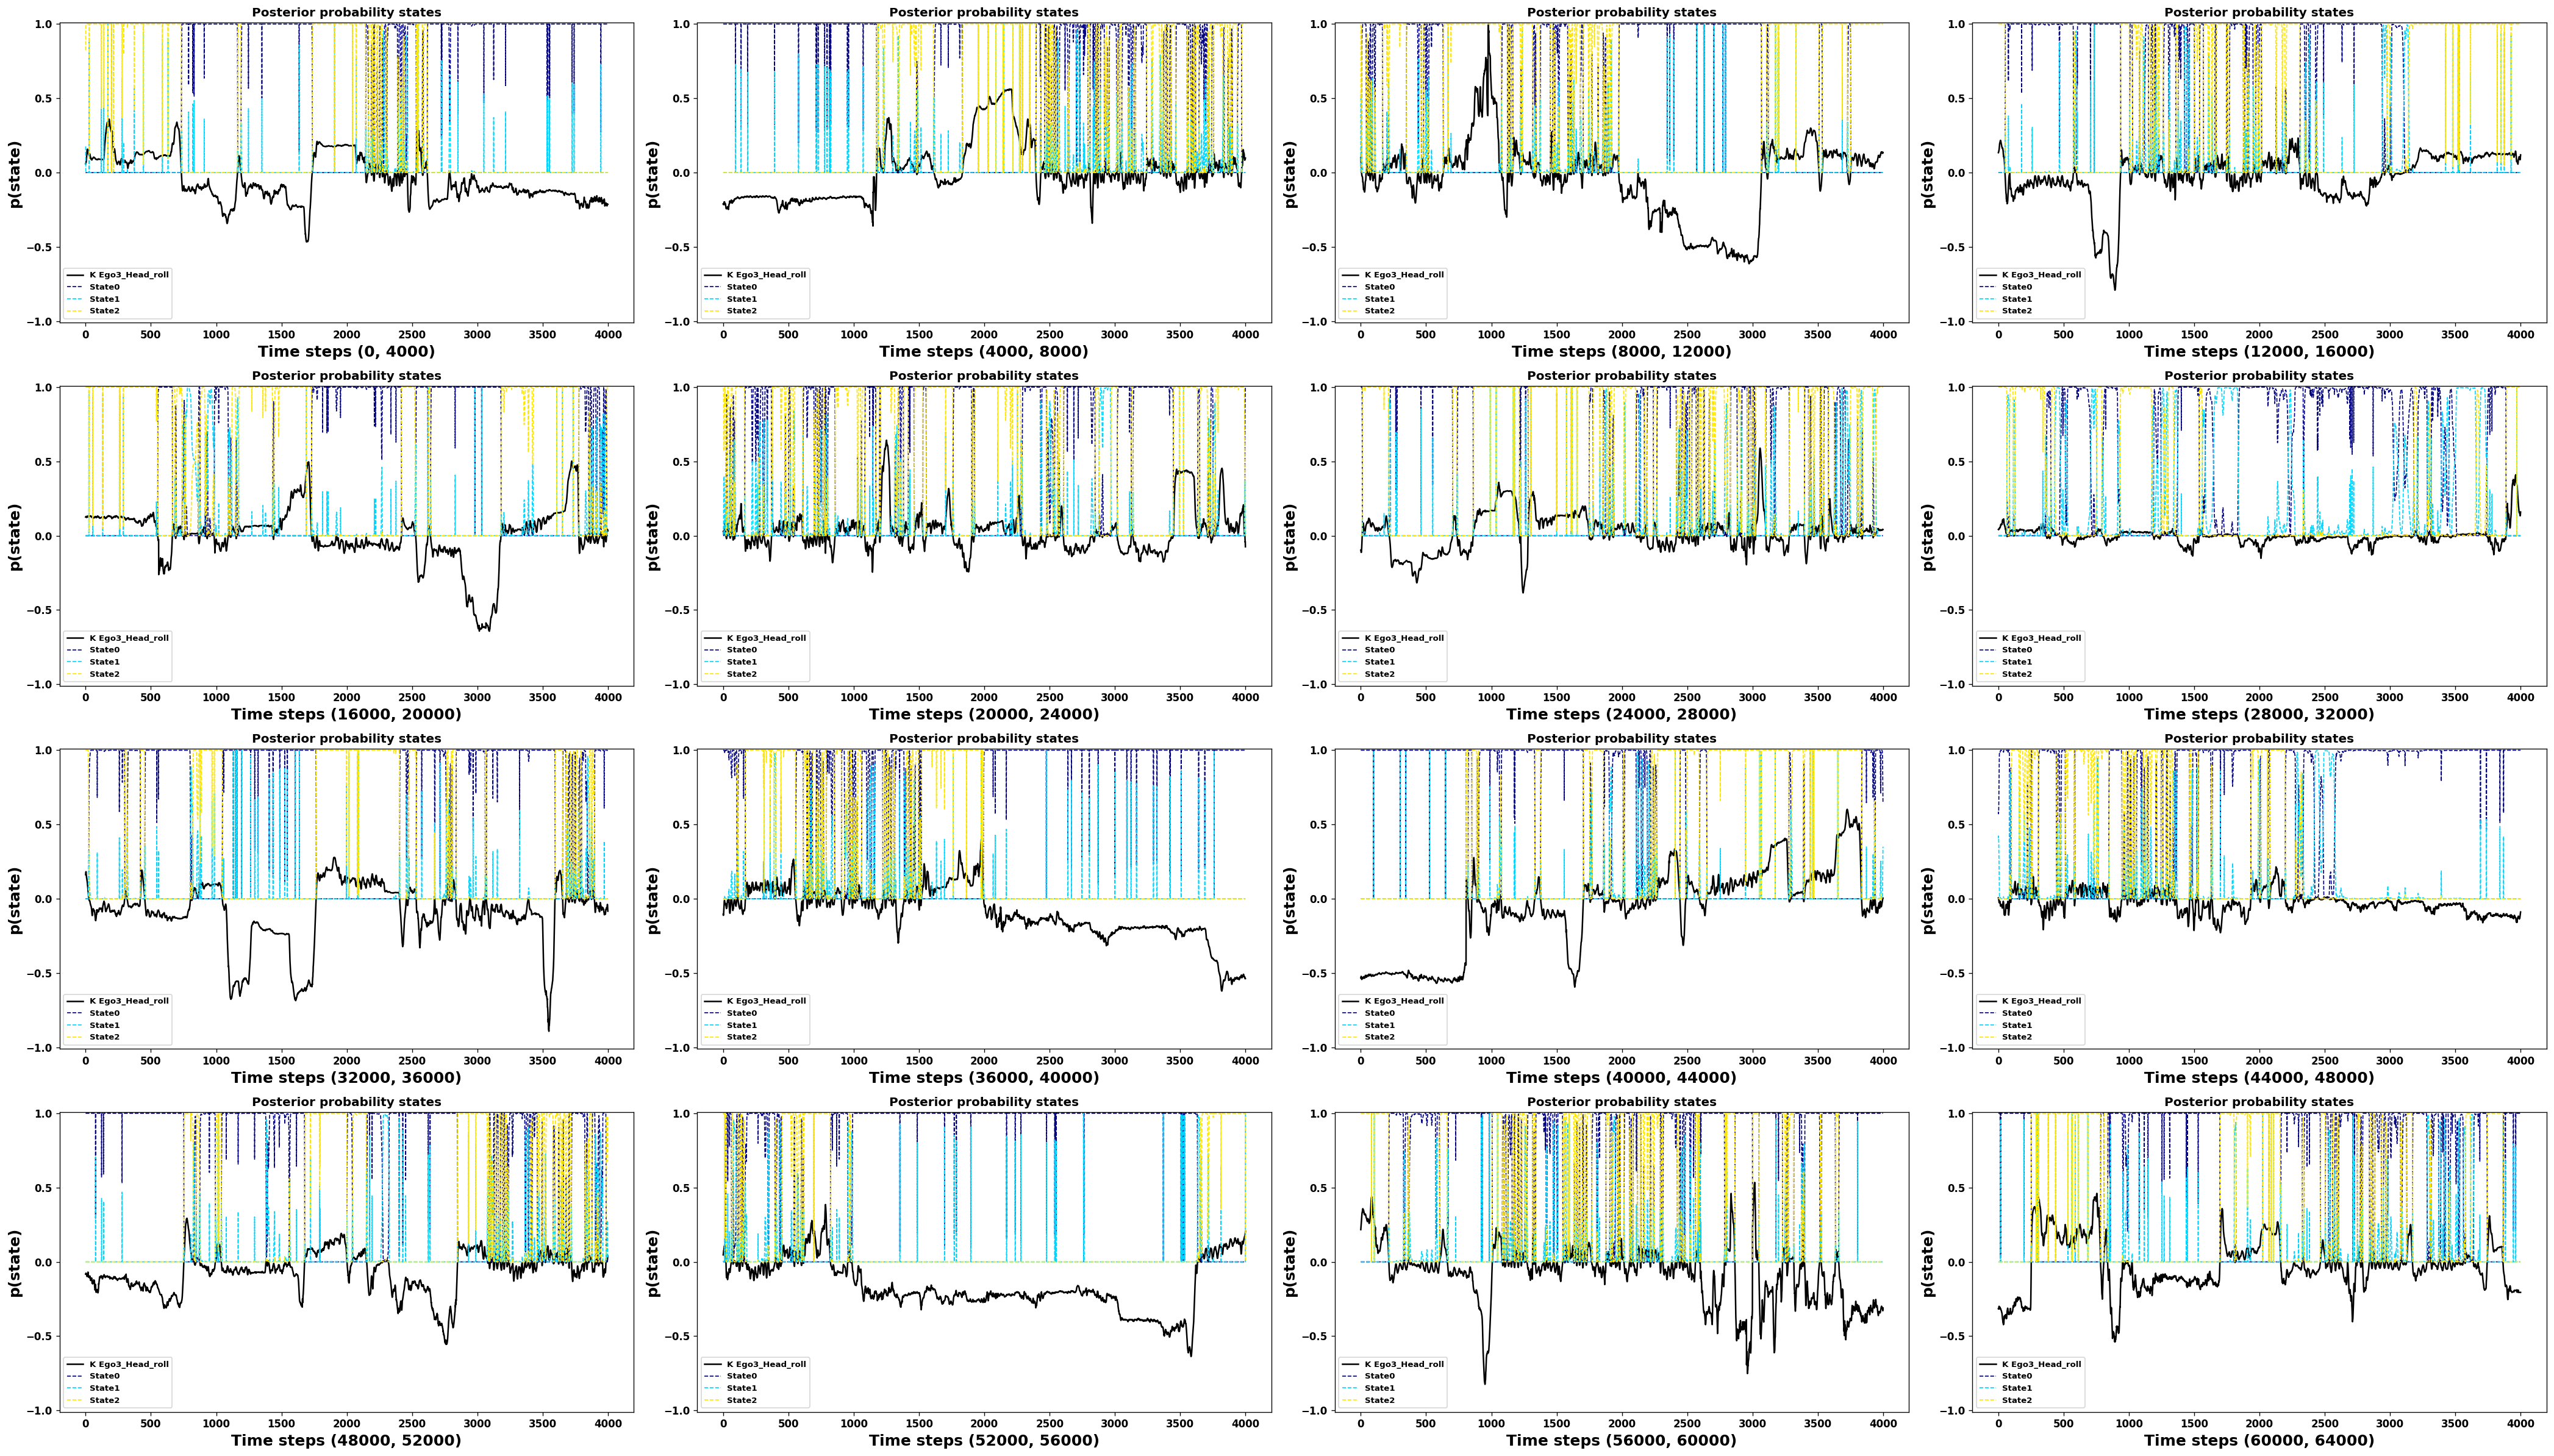

In [19]:
posterior_prob_per_states_with_predictor(path_analysis_dir, path_info_dir, data_continous_ratemaps, posterior_probs_list=posterior_probs_list,
                                             tot_masked_indices_list=tot_masked_indices_list, T_list=T_list,
                                             pred_index=2)